In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings 
warnings.filterwarnings('ignore')

In [4]:
df=pd.read_csv('diabetes.csv')
df.head()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               768 non-null    int64  
 1   Glucose                   768 non-null    int64  
 2   BloodPressure             768 non-null    int64  
 3   SkinThickness             768 non-null    int64  
 4   Insulin                   768 non-null    int64  
 5   BMI                       768 non-null    float64
 6   DiabetesPedigreeFunction  768 non-null    float64
 7   Age                       768 non-null    int64  
 8   Outcome                   768 non-null    int64  
dtypes: float64(2), int64(7)
memory usage: 54.1 KB


In [6]:
df.isnull().sum()

Pregnancies                 0
Glucose                     0
BloodPressure               0
SkinThickness               0
Insulin                     0
BMI                         0
DiabetesPedigreeFunction    0
Age                         0
Outcome                     0
dtype: int64

In [7]:
df.describe()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
count,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000
mean,3.845052,120.894531,69.105469,20.536458,79.799479,31.992578,0.471876,33.240885,0.348958
std,3.369578,31.972618,19.355807,15.952218,115.244002,7.884160,0.331329,11.760232,0.476951
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.078000,21.000000,0.000000
25%,1.000000,99.000000,62.000000,0.000000,0.000000,27.300000,0.243750,24.000000,0.000000
50%,3.000000,117.000000,72.000000,23.000000,30.500000,32.000000,0.372500,29.000000,0.000000
75%,6.000000,140.250000,80.000000,32.000000,127.250000,36.600000,0.626250,41.000000,1.000000
max,17.000000,199.000000,122.000000,99.000000,846.000000,67.100000,2.420000,81.000000,1.000000


In [8]:
# Correlation
df.corr()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
Pregnancies,1.000000,0.129459,0.141282,-0.081672,-0.073535,0.017683,-0.033523,0.544341,0.221898
Glucose,0.129459,1.000000,0.152590,0.057328,0.331357,0.221071,0.137337,0.263514,0.466581
BloodPressure,0.141282,0.152590,1.000000,0.207371,0.088933,0.281805,0.041265,0.239528,0.065068
SkinThickness,-0.081672,0.057328,0.207371,1.000000,0.436783,0.392573,0.183928,-0.113970,0.074752
Insulin,-0.073535,0.331357,0.088933,0.436783,1.000000,0.197859,0.185071,-0.042163,0.130548
BMI,0.017683,0.221071,0.281805,0.392573,0.197859,1.000000,0.140647,0.036242,0.292695
DiabetesPedigreeFunction,-0.033523,0.137337,0.041265,0.183928,0.185071,0.140647,1.000000,0.033561,0.173844
Age,0.544341,0.263514,0.239528,-0.113970,-0.042163,0.036242,0.033561,1.000000,0.238356
Outcome,0.221898,0.466581,0.065068,0.074752,0.130548,0.292695,0.173844,0.238356,1.000000


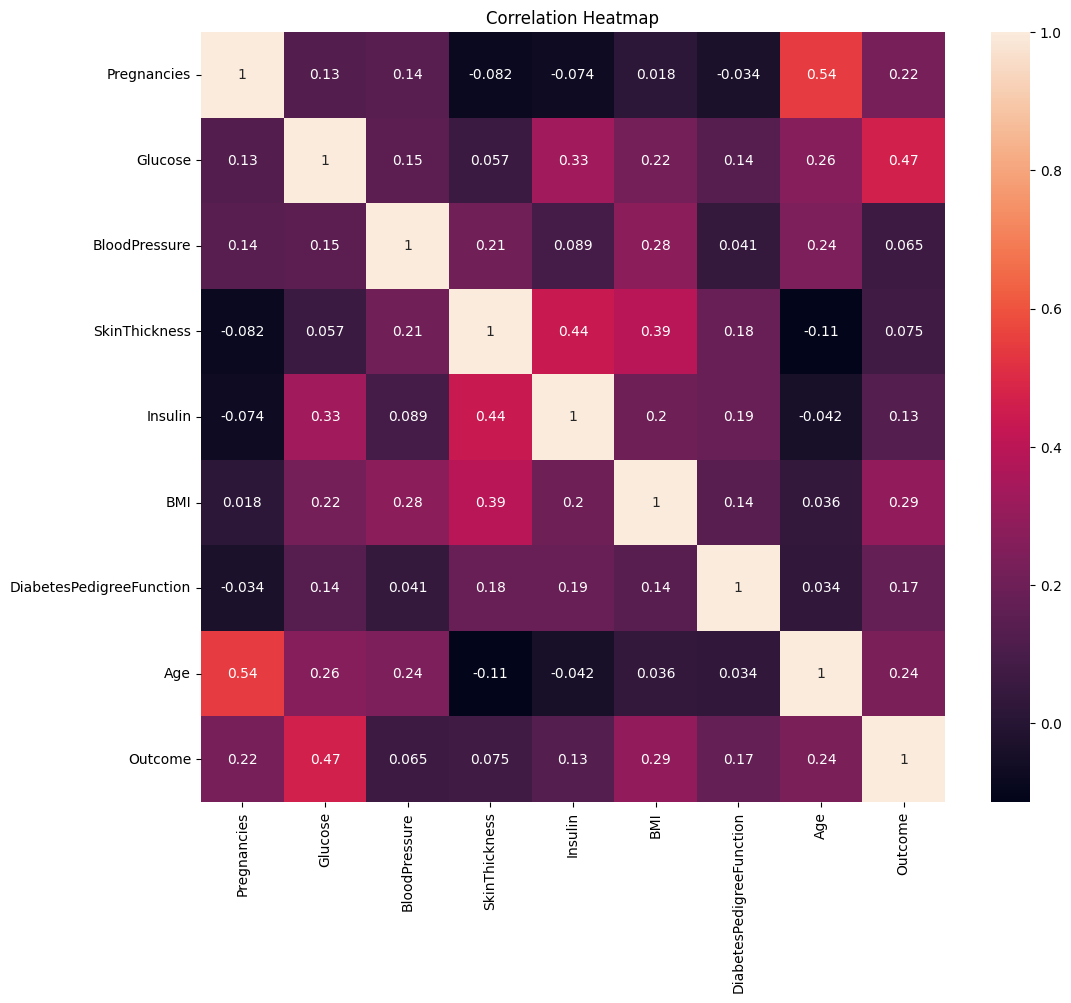

In [9]:
plt.figure(figsize=(12,10))
sns.heatmap(df.corr(),annot=True)
plt.title('Correlation Heatmap')
plt.show()

In [10]:
Selected_features=['Pregnancies', 'Glucose', 'BloodPressure', 'BMI', 'Age','Outcome']
df = df[Selected_features]

In [11]:
cols_with_zeros=['Glucose','BMI','BloodPressure']
df[cols_with_zeros] = df[cols_with_zeros].replace(0, np.nan)

print(df.isnull().sum())

Pregnancies       0
Glucose           5
BloodPressure    35
BMI              11
Age               0
Outcome           0
dtype: int64


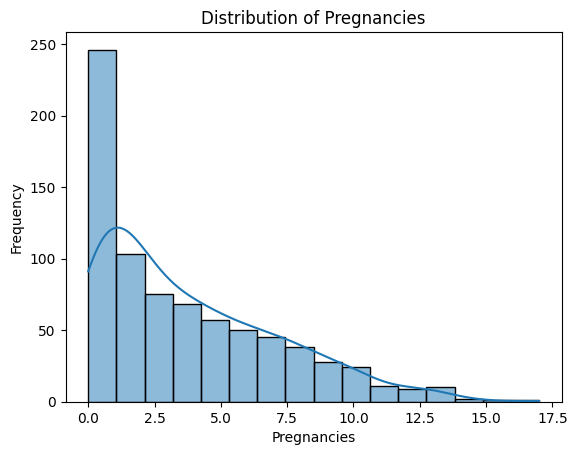

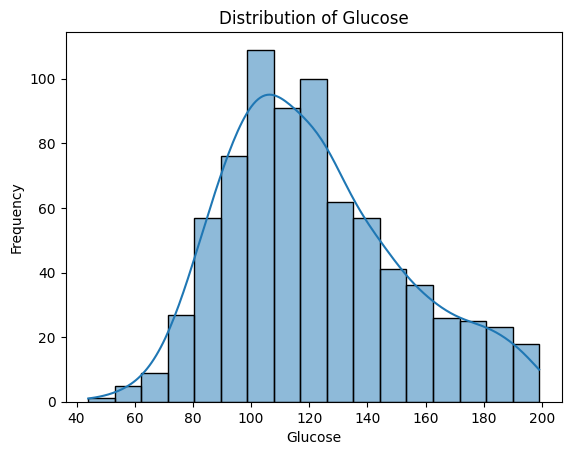

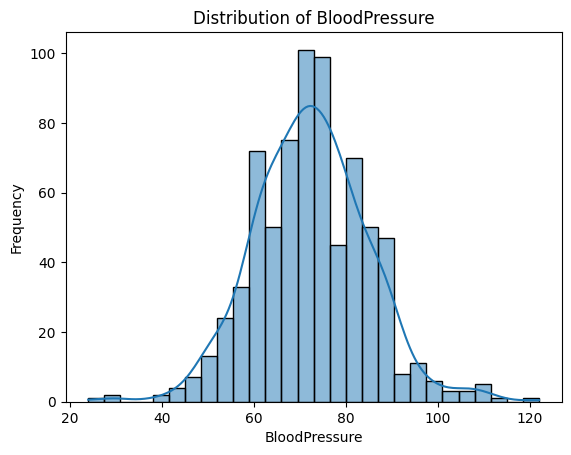

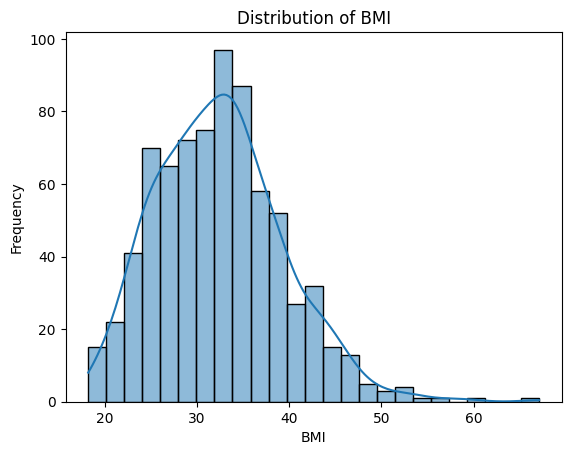

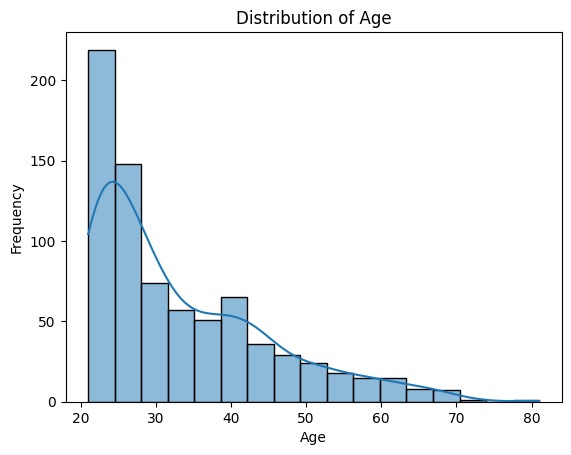

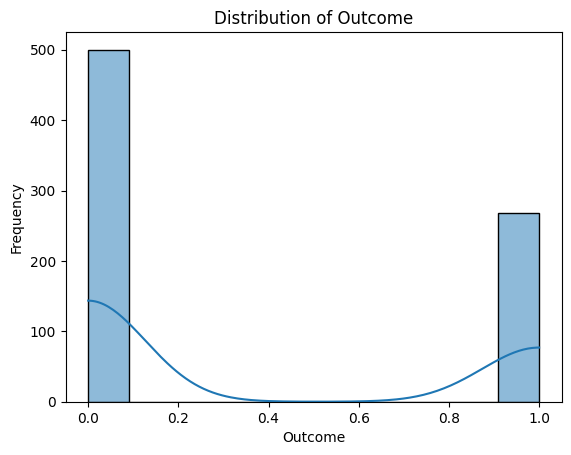

In [12]:
# Use seaborn's histplot for each feature in Selected_feature
for col in Selected_features:
	sns.histplot(df[col], kde=True)
	plt.title(f'Distribution of {col}')
	plt.xlabel(col)
	plt.ylabel('Frequency')
	plt.show()


In [13]:
# Fill missing values with median (more robust than mean)
df.fillna(df.median(), inplace=True)
print(df.isnull().sum())


Pregnancies      0
Glucose          0
BloodPressure    0
BMI              0
Age              0
Outcome          0
dtype: int64


In [14]:
X=df.drop('Outcome',axis=1)
y=df['Outcome']
print(X.shape,y.shape)

(768, 5) (768,)


In [15]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

In [16]:
pipeline=Pipeline([
    ('scalar',StandardScaler()),
    ('logistic',LogisticRegression())

])

In [17]:
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.2,random_state=42)


In [18]:
#using hypermeter tuning
from sklearn.metrics import accuracy_score,confusion_matrix,classification_report
from sklearn.model_selection import GridSearchCV

In [19]:
param_grid={
    'logistic__C': [0.001, 0.01, 0.1, 1, 10, 100],
    'logistic__penalty': ['l1', 'l2', 'elasticnet'],
    'logistic__solver': ['newton-cg', 'lbfgs', 'liblinear', 'sag', 'saga']
}


In [20]:
from sklearn.model_selection import StratifiedKFold
cv=StratifiedKFold(n_splits=5,shuffle=True,random_state=42)

In [21]:
grid=GridSearchCV(pipeline,param_grid=param_grid,cv=cv,scoring='accuracy',n_jobs=-1)
grid

GridSearchCV(cv=StratifiedKFold(n_splits=5, random_state=42, shuffle=True),
             estimator=Pipeline(steps=[('scalar', StandardScaler()),
                                       ('logistic', LogisticRegression())]),
             n_jobs=-1,
             param_grid={'logistic__C': [0.001, 0.01, 0.1, 1, 10, 100],
                         'logistic__penalty': ['l1', 'l2', 'elasticnet'],
                         'logistic__solver': ['newton-cg', 'lbfgs', 'liblinear',
                                              'sag', 'saga']},
             scoring='accuracy')

In [22]:
grid.fit(X_train,y_train)

GridSearchCV(cv=StratifiedKFold(n_splits=5, random_state=42, shuffle=True),
             estimator=Pipeline(steps=[('scalar', StandardScaler()),
                                       ('logistic', LogisticRegression())]),
             n_jobs=-1,
             param_grid={'logistic__C': [0.001, 0.01, 0.1, 1, 10, 100],
                         'logistic__penalty': ['l1', 'l2', 'elasticnet'],
                         'logistic__solver': ['newton-cg', 'lbfgs', 'liblinear',
                                              'sag', 'saga']},
             scoring='accuracy')

In [23]:
grid.best_params_

{'logistic__C': 0.1,
 'logistic__penalty': 'l1',
 'logistic__solver': 'liblinear'}

In [24]:
grid.best_score_

np.float64(0.7670798347327735)

In [25]:
y_pred=grid.predict(X_test)

In [26]:
print(f'Accuracy score: {accuracy_score(y_test,y_pred)}')
print(f'confusion_matrix: {confusion_matrix(y_test,y_pred)}')
print(f'classification_report: {classification_report(y_test,y_pred)}')


Accuracy score: 0.7532467532467533
confusion_matrix: [[82 17]
 [21 34]]
classification_report:               precision    recall  f1-score   support

           0       0.80      0.83      0.81        99
           1       0.67      0.62      0.64        55

    accuracy                           0.75       154
   macro avg       0.73      0.72      0.73       154
weighted avg       0.75      0.75      0.75       154



In [27]:
from sklearn.metrics import roc_auc_score,roc_curve
y_prob=grid.predict_proba(X_test)[:,1]
fbr,tpr,thresholds=roc_curve(y_test,y_prob)
auc_score=roc_auc_score(y_test,y_prob)


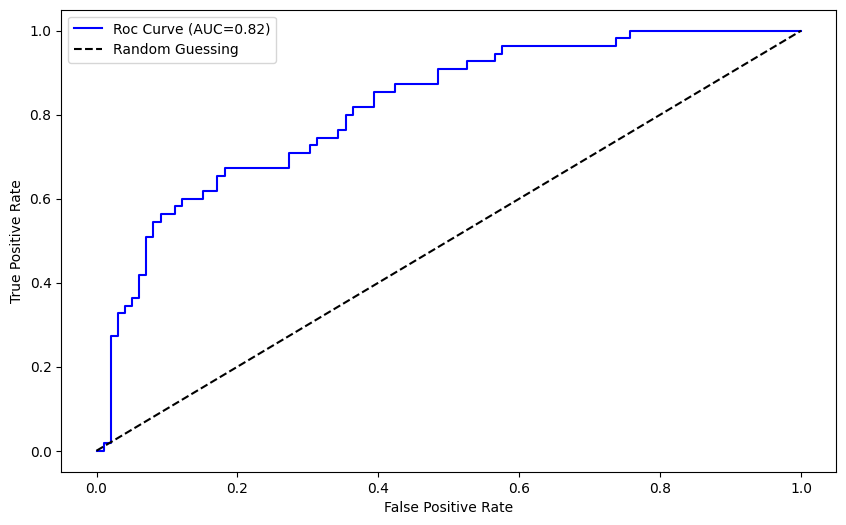

In [28]:
plt.figure(figsize=(10,6))
plt.plot(fbr, tpr, label=f'Roc Curve (AUC={auc_score:.2f})', color='blue')
plt.plot([0, 1], [0, 1], 'k--', label='Random Guessing')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.legend()
plt.show()

If AUC = 0.85:

This means: 85% of the time, the model can distinguish between diabetic and non-diabetic patients.

Higher AUC → better performance

In [31]:
import os
import pickle

os.makedirs('models', exist_ok=True)

with open('models/model.pkl', 'wb') as f:
    pickle.dump(grid, f)